# 09 – Model: LightGBM with Spatial Cross-Validation

Trains a LightGBM classifier to predict whether a hexagon has a bubble tea shop,
based on location fundamentals (people, transit, students, commercial activity).
The predicted probability serves as a **location suitability score**.

**Features (8):** distance to station, distance to campus, high schools within 1 km,
food & drink places within 500 m, residents aged 15–34 within ~1 km, median household
income, share aged 15–34, population density.

**Validation**
- **Spatial cross-validation:** hexagons are grouped into 25 blocks using their H3
  resolution-6 parent (~36 km² each). Whole blocks are held out together with
  `StratifiedGroupKFold` (5 folds), so the model is tested on areas it hasn't seen.
- A random 5-fold split is run for comparison.
- Model settings are kept simple (small trees, 200 rounds) given the dataset size (846 rows).

**Results (mean ± std across folds)**
| Split | ROC AUC | Avg precision |
|---|---|---|
| Random | 0.858 ± 0.021 | 0.507 ± 0.080 |
| Spatial | 0.851 ± 0.028 | 0.476 ± 0.120 |

Average precision of 0.476 is about 4.3× the random baseline of 0.111 (the share of
hexagons with a shop).

**Interpretation:** spatial performance is close to the random split, which indicates
the model learned general patterns that transfer to unseen

In [3]:
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import h3
from lightgbm import LGBMClassifier
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score

gdf = gpd.read_file("../data/processed/model_features.gpkg")

FEATURES = [
    "dist_station_m", "dist_campus_m", "high_schools_1km", "food_places_500m",
    "catchment_15_34", "median_hh_income", "share_15_34", "pop_density",
]
X = gdf[FEATURES]
y = gdf["has_bubble_tea"]
print("Hexagons:", len(X), "| Share with a shop:", round(y.mean(), 3))

Hexagons: 846 | Share with a shop: 0.111


Spatial blocks: 25


Text(0.5, 1.0, 'Spatial blocks used for cross-validation')

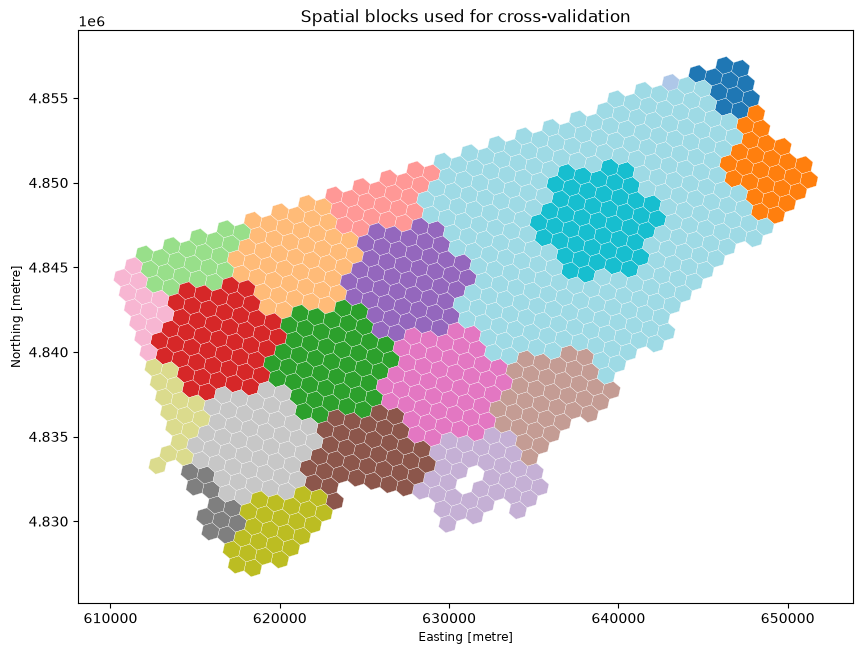

In [4]:
gdf["block"] = gdf["h3_id"].apply(lambda c: h3.cell_to_parent(c, 6))
print("Spatial blocks:", gdf["block"].nunique())

gdf.plot(column="block", categorical=True, cmap="tab20", figsize=(10, 10),
         edgecolor="white", linewidth=0.2)
plt.title("Spatial blocks used for cross-validation")

In [7]:
PARAMS = dict(
    n_estimators=200, learning_rate=0.05, num_leaves=15, min_child_samples=20,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
    random_state=42, verbose=-1,
)

def evaluate(cv, groups=None):
    """Train and test on each fold; return out-of-fold predictions and fold scores."""
    oof = np.zeros(len(y))
    aucs, aps = [], []
    for train_idx, test_idx in cv.split(X, y, groups):
        model = LGBMClassifier(**PARAMS)
        model.fit(X.iloc[train_idx], y.iloc[train_idx])
        p = model.predict_proba(X.iloc[test_idx])[:, 1]
        oof[test_idx] = p
        aucs.append(roc_auc_score(y.iloc[test_idx], p))
        aps.append(average_precision_score(y.iloc[test_idx], p))
    return oof, np.array(aucs), np.array(aps)

In [10]:
random_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
spatial_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

oof_random, auc_r, ap_r = evaluate(random_cv)
oof_spatial, auc_s, ap_s = evaluate(spatial_cv, groups=gdf["block"])

def fmt(scores):
    return f"{scores.mean():.3f} ± {scores.std():.3f}"

results = pd.DataFrame(
    {"ROC AUC": [fmt(auc_r), fmt(auc_s)], "Avg precision": [fmt(ap_r), fmt(ap_s)]},
    index=["Random split", "Spatial split"],
)
results

,ROC AUC,Avg precision
Random split,0.858 ± 0.021,0.507 ± 0.080
Spatial split,0.851 ± 0.028,0.476 ± 0.120


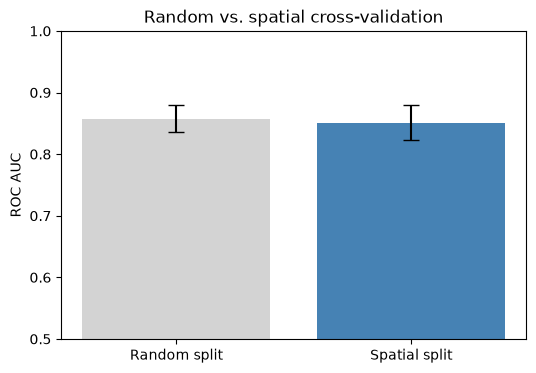

In [11]:
import os
os.makedirs("../figures", exist_ok=True)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["Random split", "Spatial split"], [auc_r.mean(), auc_s.mean()],
       yerr=[auc_r.std(), auc_s.std()], capsize=6, color=["lightgrey", "steelblue"])
ax.set_ylim(0.5, 1.0)
ax.set_ylabel("ROC AUC")
ax.set_title("Random vs. spatial cross-validation")
plt.savefig("../figures/cv_comparison.png", dpi=150, bbox_inches="tight")